In [1]:
import pandas as pd


df= pd.read_csv('long_spec_0_98_110626.csv')


top_peptides = pd.read_csv('pep_hits_wo_taxa_to_remove_less_stringent_spec_0_98_110626.csv')

peps_metadata = pd.read_csv("lassa_library_sequences_species_standardized_070726_ICTV_corrected.csv")
peps_metadata = peps_metadata.set_index('seq_id')

In [2]:
#from long to wide
plot_df = df.pivot(index='peptide', columns='individual', values='z_score')

#subset peps metadata to pep hits
pep_hits_meta = peps_metadata.loc[plot_df.index]

In [3]:
prefix_sl = ("C-", "S-")
cols = sorted([c for c in plot_df.columns if c.startswith(prefix_sl)])
cols_other = [c for c in plot_df.columns if c not in cols]
new_order = cols + cols_other
plot_df = plot_df[new_order]


n_c = sum(c.startswith("C-") for c in plot_df.columns)
n_cs = len(cols)  # all C- and S- columns

### Q: what are the overall best LASV-exposure identifying peptides? Compare survivor vs u.s. healthies peptide's z scores

In [ ]:
z_df_

In [ ]:
surv = plot_df.filter(regex='S-', axis=1)
hbdb = plot_df.filter(regex='HBDB', axis=1)

In [23]:
#binary to see the perc. of people reactive

prevalence_surv = (surv > 3).sum(axis=1) / surv.shape[1] 

prevalence_hbdb = (hbdb > 3).sum(axis=1) / hbdb.shape[1]

In [30]:
prevalence_hbdb.sort_values(ascending=False)

peptide
YP_516233.1|protein|Mammarenavirus_ippyense|?|?|?|?|L|Dak_An_B_188_d|tile_8                                                     0.011494
AAA16239.1|polypeptide|Orthohantavirus_thailandense|isolate=?|?|?|?|segment=?|strain=Thai749|tile_3                             0.011494
YP_516233.1|protein|Mammarenavirus_ippyense|?|?|?|?|L|Dak_An_B_188_d|tile_48                                                    0.011494
AAA16239.1|polypeptide|Orthohantavirus_thailandense|isolate=?|?|?|?|segment=?|strain=Thai749|tile_46                            0.011494
AAA42975.1|?|Orthonairovirus_dugbeense|isolate=?|?|?|?|segment=?|strain=?|tile_2                                                0.011494
                                                                                                                                  ...   
YP_009346022.1|polyprotein|Tapara_virus|isolate=?|Phlebotominae_sp.|Brazil|04-Feb-1983|segment=M|strain=BeAr413570|tile_23      0.000000
YP_009346019.1|polymerase|Anhanga

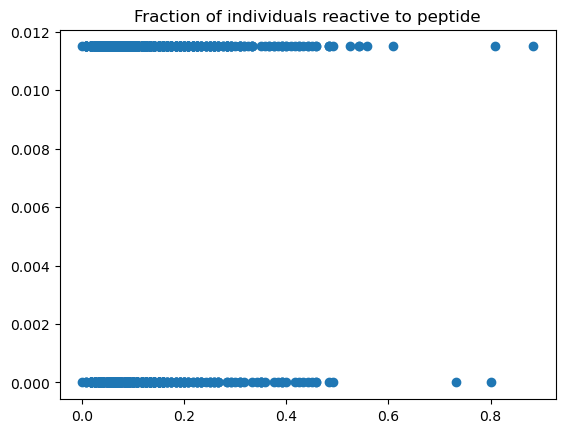

In [25]:
import matplotlib.pyplot as plt

plt.scatter(prevalence_surv, prevalence_hbdb)

plt.title('Fraction of individuals reactive to peptide')

plt.show()


### Looking at the overall peptide reactivity landscape 

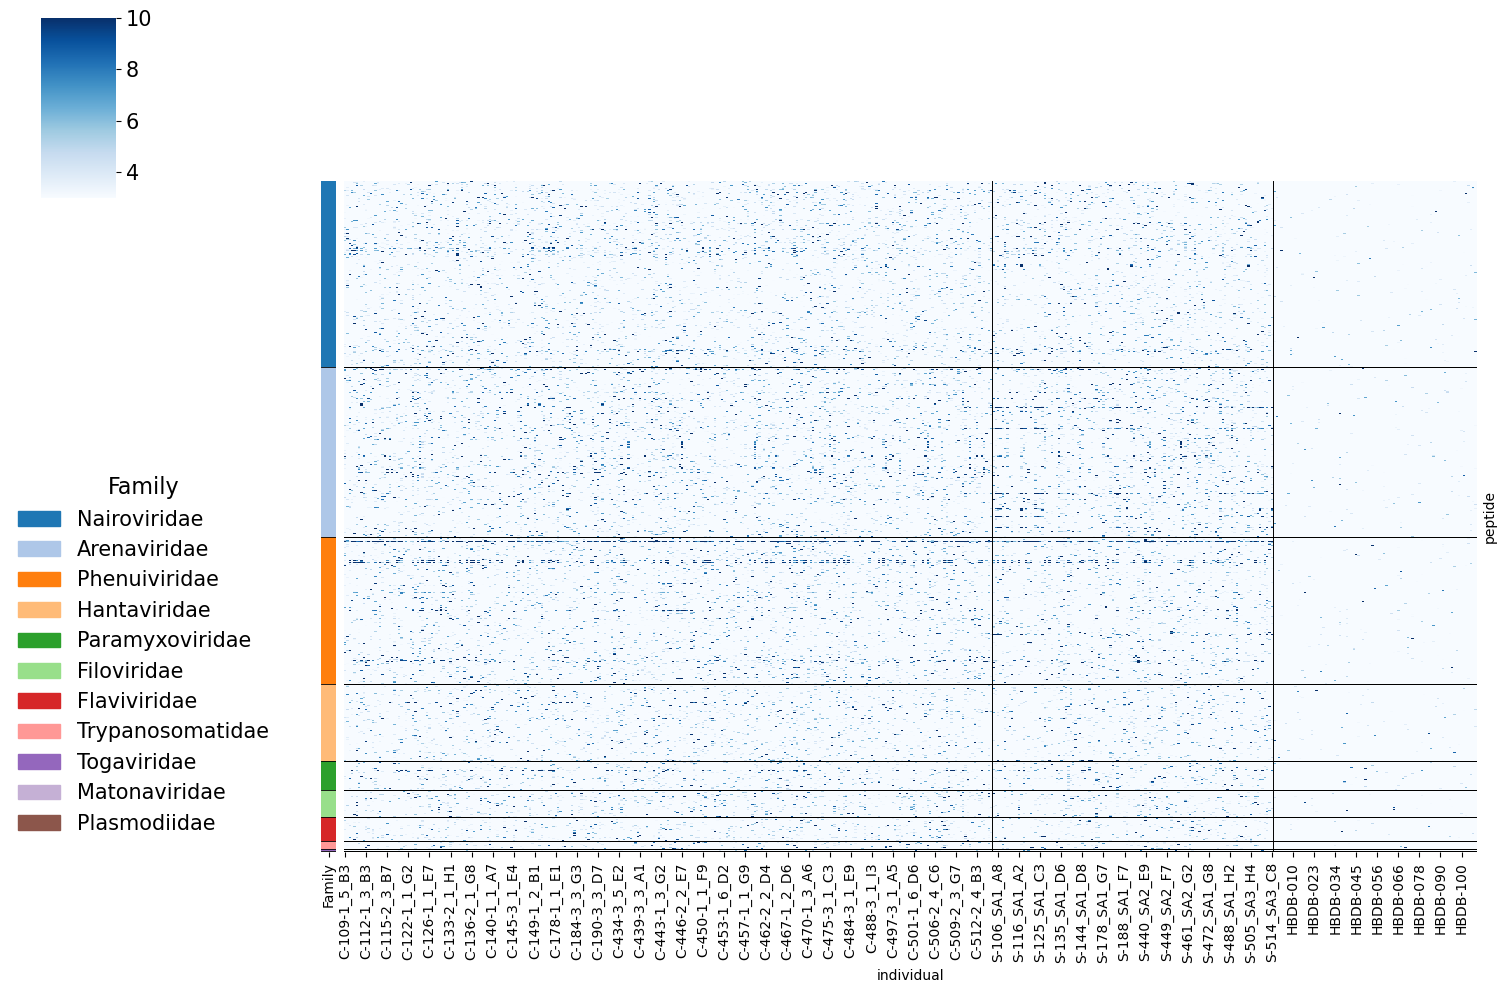

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

#sort by genus
pep_hits_meta = pep_hits_meta.sort_values(by=['family', 'species'])

# sort families by size (largest first), then by species within each family
pep_hits_meta['family_n'] = pep_hits_meta.groupby('family')['family'].transform('size')
pep_hits_meta = pep_hits_meta.sort_values(
    by=['family_n', 'family', 'species'],
    ascending=[False, True, True],
).drop(columns='family_n')

plot_df = plot_df.reindex(pep_hits_meta.index)

genera = pep_hits_meta['family'].unique()   # now ordered largest -> smallest

plot_df = plot_df.reindex(pep_hits_meta.index)

#one color per genus
genera = pep_hits_meta['family'].unique() #order follows the sort

palette = sns.color_palette('tab20', n_colors=len(genera))
genus_lut = dict(zip(genera, palette)) #zip pairs up two lists item by item, dict turns them into key -> value

#.map(genus_lut) swaps each genus name in the column for its color in the dictionary. 
# result is Series of color with one entry per peptide, keeps same index as pep_hits_meta
#clustermap uses that index to match each color to its row in plot_df
#.Genus changes the Series' name from the column. purely cosmetic, as clustermap will write this name next to color strip
row_colors = pep_hits_meta['family'].map(genus_lut).rename('Family')

g = sns.clustermap(
    plot_df, 
    row_cluster=False, 
    col_cluster=False, 
    row_colors=row_colors, 
    colors_ratio=0.01,
    cmap='Blues', 
    yticklabels=False, 
    rasterized=True,
    figsize=(15, 10),
    vmin=3, vmax=10
)

# group dividers
for x in (n_c, n_cs):
    g.ax_heatmap.axvline(x, color="black", lw=0.6)

handles = [mpatches.Patch(color=genus_lut[gn], label=gn) for gn in genera]
g.ax_heatmap.legend(handles=handles, title='Family', loc='lower right', frameon=False, bbox_to_anchor=(-0.05, 0),
            fontsize=15, title_fontsize=16)

g.ax_cbar.tick_params(labelsize=15)

# group dividers (samples)
for x in (n_c, n_cs):
    g.ax_heatmap.axvline(x, color="black", lw=0.6)

# family dividers (peptides)
counts = pep_hits_meta['family'].value_counts().reindex(genera)
for y in np.cumsum(counts.values)[:-1]:
    g.ax_heatmap.axhline(y, color="black", lw=0.6, snap=True, antialiased=False)
    g.ax_row_colors.axhline(y, color="black", lw=0.6)   # also across the color strip


#plt.savefig('./svg_figures/peptide_hits_birdseye_view_by_family.svg', format='svg',bbox_inches='tight')
plt.show()

258 Lassa peptides


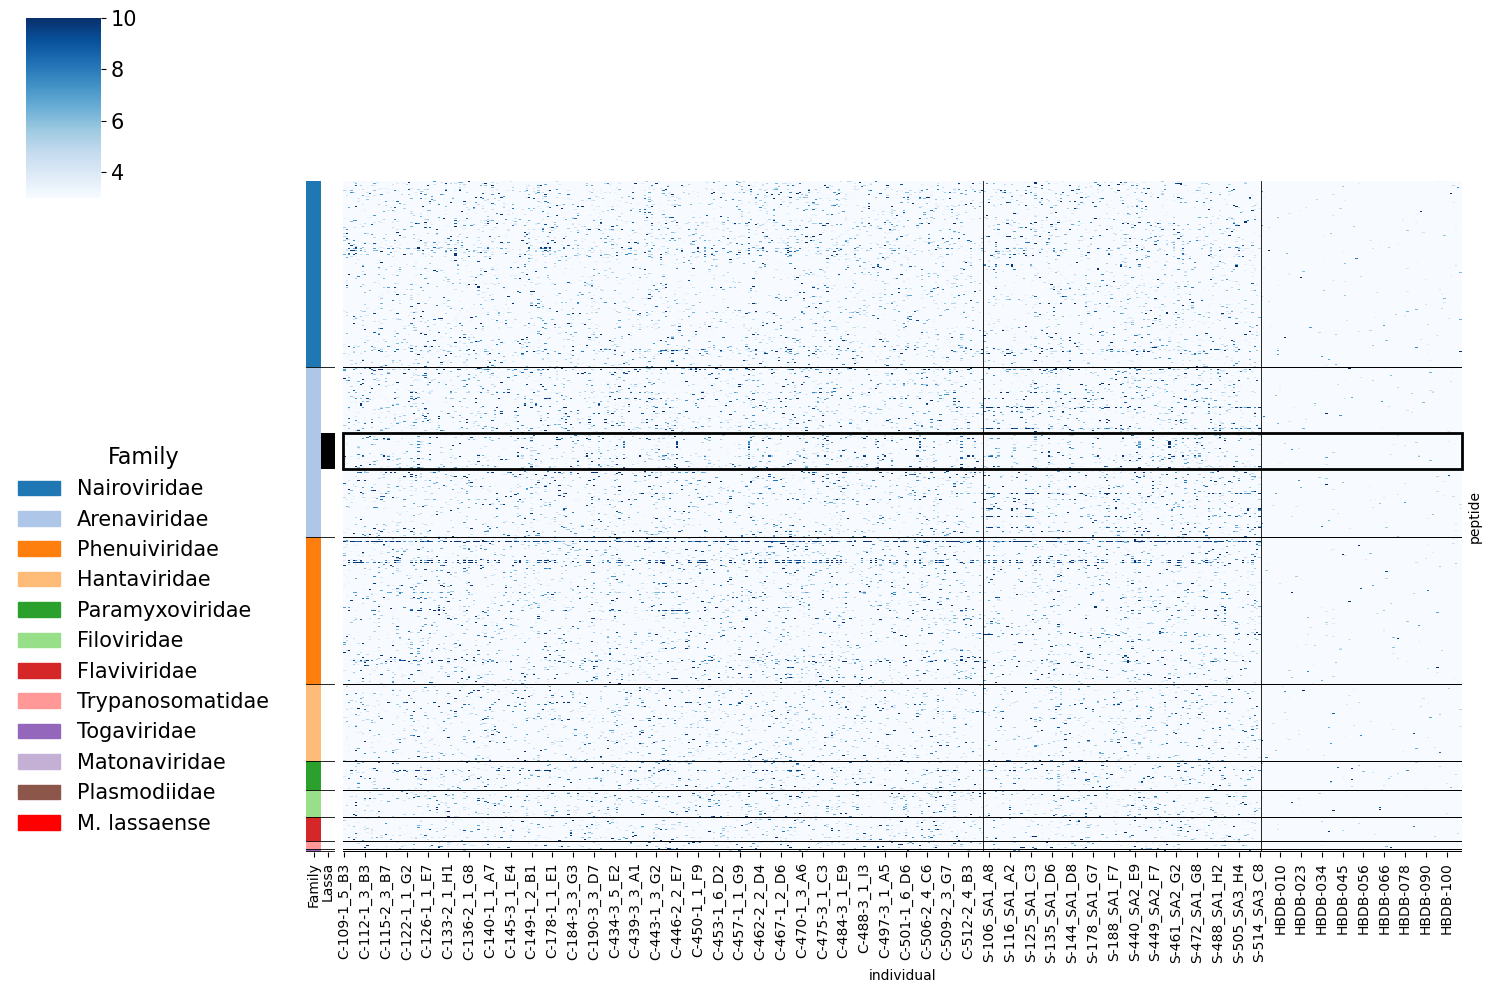

In [14]:
# flag Lassa peptides
is_lassa = pep_hits_meta['species'].eq('Mammarenavirus lassaense')
print(is_lassa.sum(), 'Lassa peptides')   # check it matched

# two color strips: family + Lassa highlight
row_colors = pd.DataFrame({
    'Family': pep_hits_meta['family'].map(genus_lut),
    'Lassa':  is_lassa.map({True: 'black', False: 'white'}),
})

g = sns.clustermap(
    plot_df,
    row_cluster=False,
    col_cluster=False,
    rasterized=True,
    row_colors=row_colors,
    colors_ratio=0.01,
    cmap='Blues',
    yticklabels=False,
    figsize=(15, 10),
    vmin=3, vmax=10,
)

# group dividers (samples)
for x in (n_c, n_cs):
    g.ax_heatmap.axvline(x, color="black", lw=0.6)

# family dividers (peptides)
counts = pep_hits_meta['family'].value_counts().reindex(genera)
for y in np.cumsum(counts.values)[:-1]:
    g.ax_heatmap.axhline(y, color="black", lw=0.6, snap=True, antialiased=False)
    g.ax_row_colors.axhline(y, color="black", lw=0.6)

# outline the Lassa block on the heatmap
rows = np.flatnonzero(is_lassa.values)
start, end = rows.min(), rows.max() + 1
g.ax_heatmap.add_patch(mpatches.Rectangle(
    (0, start), plot_df.shape[1], end - start,
    fill=False, edgecolor='black', lw=2, clip_on=False,
))

# legend
handles = [mpatches.Patch(color=genus_lut[gn], label=gn) for gn in genera]
handles.append(mpatches.Patch(color='red', label='M. lassaense'))
g.ax_heatmap.legend(handles=handles, title='Family', loc='lower right', frameon=False,
                    bbox_to_anchor=(-0.05, 0), fontsize=15, title_fontsize=16)

g.ax_cbar.tick_params(labelsize=15)

#plt.savefig('./svg_figures/peptide_hits_birdseye_view_by_famil_lassa_peps.svg', bbox_inches='tight')
plt.show()

## Subset to VHF family vs others

In [15]:
family_hits_sub_dfs = {n: g for n, g in top_peptides.groupby('family')}

               n_peptides  max_sensitivity
family                                    
Phenuiviridae        1064         0.788413
Flaviviridae          175         0.637280
Arenaviridae         1227         0.536524
Hantaviridae          555         0.526448
Nairoviridae         1340         0.501259
Filoviridae           192         0.329975


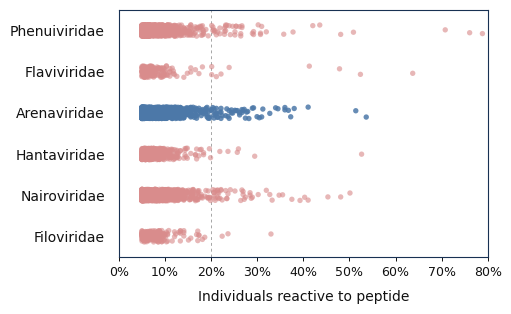

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from matplotlib.ticker import MultipleLocator, PercentFormatter


# =========================================================
# SETTINGS
# =========================================================

BROAD_THRESHOLD = 0.20
N_COHORT = 397

# Prespecified hemorrhagic-fever-associated families
VHF_FAMILIES = [
    "Arenaviridae",
    "Nairoviridae",
    "Phenuiviridae",
    "Hantaviridae",
    "Filoviridae",
    "Flaviviridae",
]


# =========================================================
# STYLE
# =========================================================

# Arenaviridae is highlighted because subsequent panels
# zoom into LASV / mammarenavirus biology
ARENAVIRIDAE_COLOR = "#4C78A8"

# Other hemorrhagic-fever-associated families:
# matches the pale-pink language of the library schematic
VHF_COLOR = "#D98C8C"

# Subtle 20% reference
THRESHOLD_COLOR = "#A6A6A6"

# Main text / axes
TEXT_COLOR = "#111111"


# =========================================================
# 1. PREPARE DATA
# =========================================================

plot_df = pd.concat(
    [
        df.assign(family=family)
        for family, df in family_hits_sub_dfs.items()
    ],
    ignore_index=True
)

plot_df["sensitivity"] = pd.to_numeric(
    plot_df["sensitivity"],
    errors="coerce"
)

plot_df = plot_df.dropna(
    subset=[
        "peptide",
        "family",
        "sensitivity"
    ]
).copy()


# =========================================================
# 2. KEEP ONLY VHF-ASSOCIATED FAMILIES
# =========================================================

vhf_df = plot_df[
    plot_df["family"].isin(VHF_FAMILIES)
].copy()


# =========================================================
# 3. FAMILY SUMMARY
# =========================================================

family_summary = (
    vhf_df
    .groupby("family")
    .agg(
        n_peptides=("peptide", "nunique"),
        max_sensitivity=("sensitivity", "max")
    )
)


# =========================================================
# 4. ORDER FAMILIES
#
# Families are ordered by their most broadly recognized
# peptide.
# =========================================================

family_order = (
    family_summary
    .sort_values(
        "max_sensitivity",
        ascending=False
    )
    .index
    .tolist()
)

print(
    family_summary.loc[family_order]
)


# =========================================================
# 5. FIGURE
# =========================================================

fig, ax = plt.subplots(
    figsize=(4.5, 3.25)
)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

rng = np.random.default_rng(42)


# =========================================================
# 6. PLOT PEPTIDES
# =========================================================

for ypos, family in enumerate(family_order):

    sub = vhf_df[
        vhf_df["family"].eq(family)
    ].copy()

    # Restrained vertical jitter
    y = ypos + rng.uniform(
        -0.14,
        0.14,
        size=len(sub)
    )


    # -----------------------------------------------------
    # COLOR
    # -----------------------------------------------------

    if family == "Arenaviridae":

        color = ARENAVIRIDAE_COLOR
        alpha = 0.85

    else:

        color = VHF_COLOR
        alpha = 0.62


    # -----------------------------------------------------
    # ALL REACTIVE PEPTIDES
    # -----------------------------------------------------

    ax.scatter(
        sub["sensitivity"],
        y,
        s=15,
        color=color,
        alpha=alpha,
        edgecolor="none",
        rasterized=True,
        zorder=2
    )


# =========================================================
# 7. 20% COHORT-REACTIVITY REFERENCE
# =========================================================

ax.axvline(
    BROAD_THRESHOLD,
    color=THRESHOLD_COLOR,
    linestyle=(0, (3, 3)),
    linewidth=0.7,
    zorder=1
)


# =========================================================
# 8. FAMILY LABELS
# =========================================================

ax.set_yticks(
    range(len(family_order))
)

ax.set_yticklabels(
    family_order,
    fontsize=10,
    color=TEXT_COLOR
)

ax.invert_yaxis()

ax.tick_params(
    axis="y",
    length=0,
    pad=10,
    colors=TEXT_COLOR
)


# =========================================================
# 9. X AXIS
# =========================================================

# Round maximum upward to nearest 10%
xmax = np.ceil(
    vhf_df["sensitivity"].max() * 10
) / 10

ax.set_xlim(
    0,
    xmax
)

ax.xaxis.set_major_locator(
    MultipleLocator(0.1)
)

ax.xaxis.set_major_formatter(
    PercentFormatter(
        xmax=1,
        decimals=0
    )
)

ax.set_xlabel(
    f"Individuals reactive to peptide",
    fontsize=10,
    color=TEXT_COLOR,
    labelpad=8
)

ax.set_ylabel("")


# =========================================================
# 10. NO GRID
#
# Keeps the panel visually consistent with the schematic
# rather than making it look like a standalone statistical
# plot.
# =========================================================

ax.grid(False)


# =========================================================
# 11. SPINES
# =========================================================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.spines["bottom"].set_color(
    TEXT_COLOR
)

ax.spines["bottom"].set_linewidth(
    0.7
)

# =========================================================
# 11. PANEL FRAME
# =========================================================

FRAME_COLOR = "#183153"   # same navy as schematic

for spine in [
    "top",
    "right",
    "bottom",
    "left"
]:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_color(FRAME_COLOR)
    ax.spines[spine].set_linewidth(0.8)

# =========================================================
# 12. X TICKS
# =========================================================

ax.tick_params(
    axis="x",
    labelsize=9,
    colors=TEXT_COLOR,
    width=0.7,
    length=3
)


# =========================================================
# 13. Y LIMITS
# =========================================================

ax.set_ylim(
    len(family_order) - 0.5,
    -0.5
)


# =========================================================
# 14. LAYOUT
# =========================================================

plt.subplots_adjust(
    left=0.17,
    right=0.99,
    bottom=0.22,
    top=0.98
)


# =========================================================
# 15. SAVE
# =========================================================

"""plt.savefig(
    "Fig1_VHF_peptide_reactivity_landscape.pdf",
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    "Fig1_VHF_peptide_reactivity_landscape.svg",
    bbox_inches="tight",
    transparent=True
)
"""
plt.show()

## How does the distribution for the most seroprevalent peptides look like per family? colored by genus


In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator


# =========================================================
# SETTINGS
# =========================================================

MIN_HITS = 20
BROAD_THRESHOLD = 0.20
MIN_BROAD_PEPTIDES = 2
N_COHORT = 397

OTHER_COLOR = "#c7c7c7"

GENUS_PALETTE = {
    "Mammarenavirus":  "#2166AC",
    "Phlebovirus":     "#1B9E77",
    "Orthonairovirus": "#D95F02",
    "Hartmanivirus":   "#7570B3",
    "Orthoflavivirus": "#2E8B57",
    "Uukuvirus":       "#E78AC3",
    "Bandavirus":      "#A6761D",
    "Orthohantavirus": "#666666",
}


# =========================================================
# 1. PREPARE DATA
# =========================================================

plot_df = pd.concat(
    [
        df.assign(family=family)
        for family, df in family_hits_sub_dfs.items()
    ],
    ignore_index=True
)

plot_df["sensitivity"] = pd.to_numeric(
    plot_df["sensitivity"],
    errors="coerce"
)

plot_df = plot_df.dropna(
    subset=["peptide", "family", "genus", "sensitivity"]
).copy()


# =========================================================
# 2. REMOVE NON-VIRAL FAMILIES
# =========================================================

NON_VIRAL_FAMILIES = [
    "Trypanosomatidae",
]

plot_df = plot_df[
    ~plot_df["family"].isin(NON_VIRAL_FAMILIES)
].copy()


# =========================================================
# 3. KEEP FAMILIES WITH >= MIN_HITS UNIQUE PEPTIDES
# =========================================================

family_counts = (
    plot_df
    .groupby("family")["peptide"]
    .nunique()
)

families_keep = family_counts[
    family_counts >= MIN_HITS
].index

plot_df = plot_df[
    plot_df["family"].isin(families_keep)
].copy()


# =========================================================
# 4. IDENTIFY GENERA WITH RECURRENT BROAD REACTIVITY
#
# Highlight only genera containing >=2 unique peptides
# individually reactive in >=20% of the cohort.
# =========================================================

genus_broad_summary = (
    plot_df.loc[
        plot_df["sensitivity"] >= BROAD_THRESHOLD
    ]
    .groupby("genus")
    .agg(
        n_broad_peptides=("peptide", "nunique"),
        max_sensitivity=("sensitivity", "max")
    )
    .sort_values(
        ["n_broad_peptides", "max_sensitivity"],
        ascending=[False, False]
    )
)

highlight_genera = (
    genus_broad_summary.loc[
        genus_broad_summary["n_broad_peptides"]
        >= MIN_BROAD_PEPTIDES
    ]
    .index
    .tolist()
)


# Unresolved / legacy taxonomic labels remain gray
UNRESOLVED_GENERA = [
    "Arenavirus",
]

highlight_genera = [
    genus
    for genus in highlight_genera
    if genus not in UNRESOLVED_GENERA
]


print("Genus-level broad reactivity summary:")
print(genus_broad_summary)

print("\nGenera highlighted:")
print(highlight_genera)


# =========================================================
# 5. CHECK THAT ALL HIGHLIGHTED GENERA HAVE COLORS
# =========================================================

missing_genera = [
    genus
    for genus in highlight_genera
    if genus not in GENUS_PALETTE
]

if missing_genera:
    raise ValueError(
        f"Missing colors for highlighted genera: {missing_genera}"
    )


# =========================================================
# 6. FAMILY SUMMARY
#
# Order families by their most broadly recognized peptide.
# =========================================================

family_summary = (
    plot_df
    .groupby("family")
    .agg(
        n_peptides=("peptide", "nunique"),
        max_sensitivity=("sensitivity", "max"),
        median_sensitivity=("sensitivity", "median")
    )
    .sort_values(
        "max_sensitivity",
        ascending=False
    )
)

family_order = family_summary.index.tolist()


# Highest maximum prevalence at top
y_positions = {
    family: len(family_order) - 1 - i
    for i, family in enumerate(family_order)
}


# =========================================================
# 7. FIGURE
# =========================================================

fig, ax = plt.subplots(
    figsize=(9.5, 5.8)
)

rng = np.random.default_rng(42)


# =========================================================
# 8. PLOT PEPTIDES
# =========================================================

for family in family_order:

    ypos = y_positions[family]

    sub = plot_df[
        plot_df["family"] == family
    ].copy()

    # restrained vertical jitter
    y = ypos + rng.uniform(
        -0.20,
        0.20,
        size=len(sub)
    )


    # -----------------------------------------------------
    # Define categories
    # -----------------------------------------------------

    is_highlight_genus = sub["genus"].isin(
        highlight_genera
    )

    is_broad = (
        sub["sensitivity"] >= BROAD_THRESHOLD
    )


    # -----------------------------------------------------
    # A. OTHER GENERA
    # small + gray
    # -----------------------------------------------------

    mask = ~is_highlight_genus

    ax.scatter(
        sub.loc[mask, "sensitivity"],
        y[mask.to_numpy()],
        s=11,
        color=OTHER_COLOR,
        alpha=0.50,
        edgecolor="none",
        rasterized=True,
        zorder=2
    )


    # -----------------------------------------------------
    # B. HIGHLIGHTED GENERA, BUT <20%
    # colored + small
    # -----------------------------------------------------

    mask = (
        is_highlight_genus
        & ~is_broad
    )

    colors = [
        GENUS_PALETTE[g]
        for g in sub.loc[mask, "genus"]
    ]

    ax.scatter(
        sub.loc[mask, "sensitivity"],
        y[mask.to_numpy()],
        c=colors,
        s=12,
        alpha=0.60,
        edgecolor="none",
        rasterized=True,
        zorder=3
    )


    # -----------------------------------------------------
    # C. HIGHLIGHTED GENERA AND >=20%
    # colored + large
    # -----------------------------------------------------

    mask = (
        is_highlight_genus
        & is_broad
    )

    colors = [
        GENUS_PALETTE[g]
        for g in sub.loc[mask, "genus"]
    ]

    ax.scatter(
        sub.loc[mask, "sensitivity"],
        y[mask.to_numpy()],
        c=colors,
        s=30,
        alpha=0.95,
        edgecolor="white",
        linewidth=0.35,
        rasterized=True,
        zorder=4
    )


    # -----------------------------------------------------
    # Family median
    # -----------------------------------------------------

    median = sub["sensitivity"].median()

    ax.plot(
        [median, median],
        [ypos - 0.25, ypos + 0.25],
        color="black",
        linewidth=1.6,
        solid_capstyle="butt",
        zorder=5
    )


# =========================================================
# 9. 20% REACTIVITY THRESHOLD
# =========================================================

ax.axvline(
    BROAD_THRESHOLD,
    color="#555555",
    linestyle=(0, (3, 2)),
    linewidth=1.0,
    zorder=1
)


# =========================================================
# 10. FAMILY LABELS
#
# Family = black
# peptide count = gray
# =========================================================

yticks = [
    y_positions[family]
    for family in family_order
]

ax.set_yticks(yticks)

ax.set_yticklabels(
    family_order,
    fontsize=10.5,
    color="black"
)

for label in ax.get_yticklabels():
    label.set_horizontalalignment("right")


# peptide counts
for family in family_order:

    ypos = y_positions[family]

    n_peptides = int(
        family_summary.loc[
            family,
            "n_peptides"
        ]
    )

    ax.annotate(
        f"({n_peptides} peptides)",
        xy=(0, ypos),
        xycoords=(
            ax.get_yaxis_transform(),
            "data"
        ),
        xytext=(-8, -11),
        textcoords="offset points",
        ha="right",
        va="center",
        fontsize=7.7,
        color="#808080",
        annotation_clip=False
    )


# =========================================================
# 11. X AXIS
# =========================================================

xmax = max(
    plot_df["sensitivity"].max() * 1.04,
    0.30
)

ax.set_xlim(
    0,
    xmax
)

ax.xaxis.set_major_locator(
    MultipleLocator(0.1)
)

ax.set_xlabel(
    f"Fraction of cohort reactive to peptide (n = {N_COHORT})",
    fontsize=9.5,
    color="black",
    labelpad=7
)

ax.set_ylabel("")


# =========================================================
# 12. GRID
# =========================================================

ax.grid(
    axis="x",
    color="#e6e6e6",
    linewidth=0.65
)

ax.set_axisbelow(True)


# =========================================================
# 13. AXES
# =========================================================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#4d4d4d")
ax.spines["bottom"].set_color("#4d4d4d")

ax.spines["left"].set_linewidth(0.7)
ax.spines["bottom"].set_linewidth(0.7)

ax.tick_params(
    axis="x",
    labelsize=8.5,
    colors="#333333",
    width=0.7,
    length=3.5
)

ax.tick_params(
    axis="y",
    colors="black",
    width=0.7,
    length=4,
    pad=8
)


# =========================================================
# 14. Y LIMITS
# =========================================================

top_y = max(
    y_positions.values()
)

ax.set_ylim(
    -0.55,
    top_y + 0.55
)


# =========================================================
# 15. GENUS LEGEND
# =========================================================

genus_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="none",
        markersize=6.5,
        markerfacecolor=GENUS_PALETTE[genus],
        markeredgecolor="none",
        label=genus
    )
    for genus in highlight_genera
]

# gray category
genus_handles.append(
    Line2D(
        [0], [0],
        marker="o",
        linestyle="none",
        markersize=6.5,
        markerfacecolor=OTHER_COLOR,
        markeredgecolor="none",
        label="Other genera"
    )
)


genus_legend = ax.legend(
    handles=genus_handles,
    title="Genus",
    frameon=False,

    # position
    bbox_to_anchor=(1.06, 1.0),
    loc="upper left",
    borderaxespad=0,

    # typography
    fontsize=9,
    title_fontsize=10,

    # spacing
    handletextpad=0.65,
    labelspacing=0.55,
    borderpad=0,
    handlelength=1.0
)

genus_legend.get_title().set_fontweight(
    "semibold"
)

ax.add_artist(genus_legend)


# =========================================================
# 16. FAMILY MEDIAN LEGEND
# =========================================================

median_handle = Line2D(
    [0], [0],
    color="black",
    linewidth=1.8,
    label="Family median"
)

ax.legend(
    handles=[median_handle],
    frameon=False,

    # aligned with genus legend
    bbox_to_anchor=(1.06, 0.53),
    loc="upper left",
    borderaxespad=0,

    fontsize=9,
    handlelength=1.8,
    handletextpad=0.65
)


# =========================================================
# 17. LAYOUT
# =========================================================

plt.subplots_adjust(
    left=0.20,
    right=0.72,
    bottom=0.14,
    top=0.97
)


# =========================================================
# 18. SAVE
# =========================================================

"""plt.savefig(
    "viral_family_peptide_reactivity_by_cohort_prevalence.svg",
    format="svg",
    bbox_inches="tight"
)

plt.savefig(
    "viral_family_peptide_reactivity_by_cohort_prevalence.pdf",
    format="pdf",
    bbox_inches="tight"
)
"""
plt.show()

Genus-level broad reactivity summary:
                 n_broad_peptides  max_sensitivity
genus                                             
Mammarenavirus                 40         0.536524
Orthonairovirus                35         0.481108
Phlebovirus                    34         0.508816
Orthoflavivirus                 9         0.637280
Uukuvirus                       7         0.264484
Hartmanivirus                   6         0.340050
Orthohantavirus                 5         0.526448
Bandavirus                      4         0.788413
Henipavirus                     4         0.345088
Arenavirus                      4         0.299748
Norwavirus                      3         0.501259
Reptarenavirus                  3         0.327456
Antennavirus                    2         0.410579
Sitinavirus                     2         0.347607
Ocetevirus                      2         0.224181
Orthoebolavirus                 1         0.329975
Striwavirus                     1         0.

ValueError: Missing colors for highlighted genera: ['Henipavirus', 'Norwavirus', 'Reptarenavirus', 'Antennavirus', 'Sitinavirus', 'Ocetevirus']

In [ ]:
arenavirus_rows = plot_df[
    plot_df["genus"].str.strip().str.lower() == "arenavirus"
]

print(
    arenavirus_rows[
        ["peptide", "family", "genus"]
    ].to_string(index=False)
)

                                                                                                                        peptide       family      genus
ADX32837.1|nucleoprotein|Gbagroube_virus|?|Mus_setulosus|Cote_d'Ivoire:_Gbagroube-_Prefecture_de_Divo|Mar-2005|S|CIV608|tile_12 Arenaviridae Arenavirus
 ADX32837.1|nucleoprotein|Gbagroube_virus|?|Mus_setulosus|Cote_d'Ivoire:_Gbagroube-_Prefecture_de_Divo|Mar-2005|S|CIV608|tile_6 Arenaviridae Arenavirus
    ADX32840.1|precursor|Menekre_virus|?|Hylomyscus_sp.|Cote_d'Ivoire:_Menekre-_Prefecture_de_Gagnoa|Nov-2005|S|CIV1227|tile_14 Arenaviridae Arenavirus
 ADX32841.1|nucleoprotein|Menekre_virus|?|Hylomyscus_sp.|Cote_d'Ivoire:_Menekre-_Prefecture_de_Gagnoa|Nov-2005|S|CIV1227|tile_9 Arenaviridae Arenavirus
                                                  AFY05618.1|protein|Mopeia_Lassa_virus_reassortant_29|?|?|?|?|S|IGS-27|tile_16 Arenaviridae Arenavirus
                                 QIM73713.1|precursor|Arenavirus_sp.|RtRsp-AreV/Tt2018|R

### how many individuals are reactive to at least one lasv peptide?

In [ ]:
df_lasv = df.loc[df['species'] == 'Mammarenavirus lassaense']

In [ ]:
df_lasv.groupby(['individual', 'category'])['reactive'].any().reset_index().groupby('category')['reactive'].mean().round(2)

category
Household contact    0.99
Lassa survivor       1.00
US healthy           0.00
Name: reactive, dtype: float64

## top genera based on number of peptides 

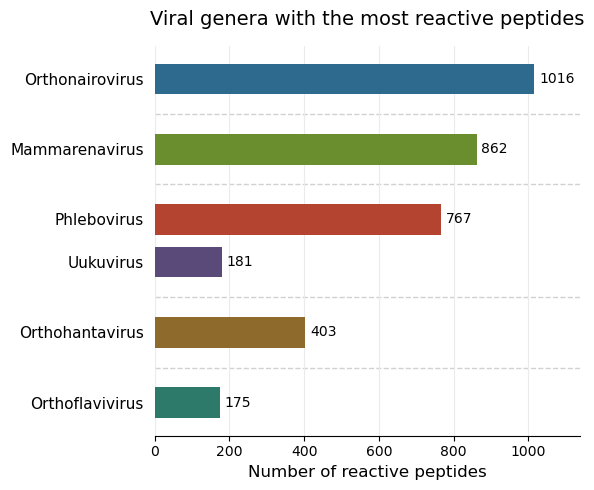

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

hits = pep_hits_meta.reset_index()

# ---------------------------------------------------------
# Consistent genus colors across figures
# ---------------------------------------------------------
GENUS_PALETTE = {
    'Orthonairovirus': '#2d6a8e',
    'Phlebovirus':     '#b4432f',
    'Mammarenavirus':  '#6a8e2d',
    'Orthohantavirus': '#8e6a2d',
    'Uukuvirus':       '#5a4a7a',
    'Orthoflavivirus': '#2d7a6a',
}

DEFAULT_COLOR = '0.70'


def plot_top_genera_grouped(hits, top_k=8, fname=None):

    # ---------------------------------------------------------
    # 1. Count unique reactive peptides per genus
    # ---------------------------------------------------------
    g = (
        hits.groupby(["family", "genus"])["peptide"]
            .nunique()
            .reset_index(name="n")
            .sort_values("n", ascending=False)
    )

    # Select top genera OVERALL
    top = g.head(top_k).copy()

    # ---------------------------------------------------------
    # 2. Order families by strongest genus
    # ---------------------------------------------------------
    family_order = (
        top.groupby("family")["n"]
           .max()
           .sort_values(ascending=False)
           .index
           .tolist()
    )

    # ---------------------------------------------------------
    # 3. Build plotting order + gaps between families
    # ---------------------------------------------------------
    rows = []
    y_positions = []
    separators = []

    y = 0
    gap = 0.65

    for i, fam in enumerate(family_order):

        fam_df = (
            top[top["family"] == fam]
            .sort_values("n", ascending=False)
        )

        for _, row in fam_df.iterrows():
            rows.append(row)
            y_positions.append(y)
            y += 1

        # Add separator/gap between families
        if i < len(family_order) - 1:
            separators.append(y - 0.5 + gap / 2)
            y += gap

    plot_df = pd.DataFrame(rows)

    # ---------------------------------------------------------
    # 4. Plot
    # ---------------------------------------------------------
    fig, ax = plt.subplots(
        figsize=(6, 5)
    )

    ax.barh(
        y_positions,
        plot_df["n"],
        height=0.72,
        color=[
            GENUS_PALETTE.get(gen, DEFAULT_COLOR)
            for gen in plot_df["genus"]
        ],
        edgecolor="none"
    )

    # Genus labels
    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        plot_df["genus"],
        fontsize=11
    )

    # Largest family at top
    ax.invert_yaxis()

    # ---------------------------------------------------------
    # 5. Add counts
    # ---------------------------------------------------------
    xmax = plot_df["n"].max()

    for yi, n in zip(y_positions, plot_df["n"]):
        ax.text(
            n + xmax * 0.012,
            yi,
            f"{n}",
            va="center",
            ha="left",
            fontsize=10
        )

    ax.set_xlim(0, xmax * 1.12)

    # ---------------------------------------------------------
    # 6. Family separators
    # ---------------------------------------------------------
    for sep in separators:
        ax.axhline(
            sep,
            color="0.82",
            linewidth=1,
            linestyle="--",
            zorder=0
        )

    # ---------------------------------------------------------
    # 7. Labels / formatting
    # ---------------------------------------------------------
    ax.set_xlabel(
        "Number of reactive peptides",
        fontsize=12
    )

    ax.set_title(
        "Viral genera with the most reactive peptides",
        fontsize=14,
        pad=15
    )

    ax.spines[["top", "right", "left"]].set_visible(False)

    ax.tick_params(
        axis="y",
        length=0,
        pad=8
    )

    ax.grid(
        axis="x",
        color="0.92",
        linewidth=0.8
    )

    ax.set_axisbelow(True)

    plt.tight_layout()

    if fname:
        plt.savefig(
            fname,
            bbox_inches="tight",
            transparent=True
        )

    plt.show()

    return plot_df


top_genera = plot_top_genera_grouped(
    hits,
    top_k=6,
    fname="svg_figures/bar_top_genera_grouped.svg"
)

### Figure on #peptides 

## delving deeper into the Phlebovirus / Nairovirus signal. 
### 1) % of everyone tested reactive to proteins from each genus
#### 2) % of everyone tested reactive to proteins from RVFV / CCHFV species

In [ ]:
rvfv_sl = df.loc[(df['species'] == 'Phlebovirus riftense') & (df['cohort'] == 'SL') & df['reactive']]

In [ ]:
rvfv_sl_reactive_pep_count = rvfv_sl.groupby(['protein_std', 'individual'])['peptide'].size().reset_index().sort_values(by='peptide', ascending=False)
rvfv_sl_reactive_pep_across_proteins = rvfv_sl_reactive_pep_count.groupby('individual')['peptide'].sum()
rvfv_sl_reactive_pep_across_proteins.sort_values(ascending=False).head(3)

individual
C-114-2_1_H5    2
C-138-3_1_E8    2
C-439-1_1_I5    2
Name: peptide, dtype: int64

In [ ]:
phlebo_sl = df.loc[(df['genus'] == 'Phlebovirus') & (df['cohort'] == 'SL') & df['reactive']]
phlebo_sl_reactive_pep_count = phlebo_sl.groupby(['protein_std', 'individual'])['peptide'].size().reset_index().sort_values(by='peptide', ascending=False)

#counting reactive to a protein if has at least 3 reactive peptides to a phlebovirus protein
phlebo_sl_reactive_pep_count['reactive_min_3'] = np.where(phlebo_sl_reactive_pep_count['peptide'] >= 3, True, False)

In [ ]:
proteins = ['polymerase', 'glycoprotein', 'polyprotein',
       'nonstructural protein', 'nucleoprotein']

reactive_all = (
    #.loc() only keeps rows where this condition is true
    phlebo_sl_reactive_pep_count.loc[phlebo_sl_reactive_pep_count['reactive_min_3'] & phlebo_sl_reactive_pep_count['protein_std'].isin(proteins)]
    .groupby('individual')['protein_std'].nunique().eq(len(proteins))
)

phlebo_sl_reactive_pep_count['reactive_all_proteins'] = phlebo_sl_reactive_pep_count['sample_id'].map(reactive_all).fillna(False)

KeyError: 'sample_id'

In [ ]:
reactive_all

,protein_std,peptide,reactive_min_3,reactive_all_proteins
individual,,,,
C-109-1_5_B3,False,False,False,False
C-109-2_5_B5,False,False,False,False
C-109-3_4_E7,False,False,False,False
C-110-1_2_A5,False,False,False,False
C-110-2_3_F8,False,False,False,False
...,...,...,...,...
S-510_SA3_D5,False,False,False,False
S-511_SA5_A6,False,False,False,False
S-512_SA3_G9,False,False,False,False


In [ ]:
phlebo_sl_reactive_pep_count['protein_std'].unique()

array(['polymerase', 'glycoprotein', 'polyprotein',
       'nonstructural protein', 'nucleoprotein'], dtype=object)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

hits = pep_hits_meta.reset_index()

def plot_top_species_by_genus(
    hits,
    genera=("Mammarenavirus", "Orthonairovirus", "Orthoflavivirus"),
    top_k=2,
    fname=None
):

    # ---------------------------------------------------------
    # 1. Count unique reactive peptides per species
    # ---------------------------------------------------------
    g = (
        hits[hits["genus"].isin(genera)]
        .groupby(["family", "genus", "species"])["peptide"]
        .nunique()
        .reset_index(name="n")
    )

    # ---------------------------------------------------------
    # 2. Select top 2 species WITHIN each genus
    # ---------------------------------------------------------
    top = (
        g.sort_values("n", ascending=False)
         .groupby("genus", group_keys=False)
         .head(top_k)
         .copy()
    )

    # Keep genus order exactly as specified above
    genus_order = list(genera)

    # ---------------------------------------------------------
    # 3. SAME COLORS as previous figure
    # ---------------------------------------------------------
    genus_colors = GENUS_COLORS

    # ---------------------------------------------------------
    # 4. Build plotting positions with gaps between genera
    # ---------------------------------------------------------
    rows = []
    y_positions = []
    separators = []

    y = 0
    gap = 0.8

    for i, genus in enumerate(genus_order):

        genus_df = (
            top[top["genus"] == genus]
            .sort_values("n", ascending=False)
        )

        for _, row in genus_df.iterrows():
            rows.append(row)
            y_positions.append(y)
            y += 1

        # Add gap between genera
        if i < len(genus_order) - 1:
            separators.append(y - 0.5 + gap / 2)
            y += gap

    plot_df = pd.DataFrame(rows)

    # ---------------------------------------------------------
    # 5. Plot
    # ---------------------------------------------------------
    fig, ax = plt.subplots(
        figsize=(13, 7)
    )

    ax.barh(
        y_positions,
        plot_df["n"],
        height=0.7,
        color=[
            genus_colors[g]
            for g in plot_df["genus"]
        ],
        edgecolor="none"
    )

    # Species labels
    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        plot_df["species"],
        fontsize=17
    )

    # Largest species at top
    ax.invert_yaxis()

    # ---------------------------------------------------------
    # 6. Add counts
    # ---------------------------------------------------------
    xmax = plot_df["n"].max()

    for yi, n in zip(y_positions, plot_df["n"]):
        ax.text(
            n + xmax * 0.015,
            yi,
            f"{n}",
            va="center",
            ha="left",
            fontsize=14
        )

    ax.set_xlim(0, xmax * 1.15)

    # ---------------------------------------------------------
    # 7. Separators between genera
    # ---------------------------------------------------------
    for sep in separators:
        ax.axhline(
            sep,
            color="0.82",
            linewidth=1.2,
            linestyle="--",
            zorder=0
        )

    # ---------------------------------------------------------
    # 8. Formatting
    # ---------------------------------------------------------
    ax.set_xlabel(
        "Number of reactive peptides",
        fontsize=16,
        labelpad=8
    )

    ax.set_title(
        "Most reactive species within selected viral genera",
        fontsize=18,
        pad=15
    )

    ax.tick_params(
        axis="x",
        labelsize=14
    )

    ax.tick_params(
        axis="y",
        length=0,
        pad=8
    )

    ax.spines[["top", "right", "left"]].set_visible(False)

    # Subtle x-axis grid
    ax.grid(
        axis="x",
        color="0.92",
        linewidth=0.8
    )

    ax.set_axisbelow(True)

    # ---------------------------------------------------------
    # 9. Legend = genus
    # ---------------------------------------------------------
    handles = [
        Patch(
            facecolor=genus_colors[genus],
            label=genus
        )
        for genus in genus_order
    ]

    ax.legend(
        handles=handles,
        title="Genus",
        frameon=False,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=13,
        title_fontsize=13
    )

    plt.tight_layout()

    if fname:
        plt.savefig(
            fname,
            bbox_inches="tight",
            transparent=True
        )

    plt.show()

    return plot_df


top_species = plot_top_species_by_genus(
    hits,
    genera=[
        "Mammarenavirus",
        "Orthonairovirus",
        "Orthoflavivirus"
    ],
    top_k=2,
    fname="svg_figures/bar_top_species_selected_genera.svg"
)

NameError: name 'GENUS_COLORS' is not defined

### what is the overall seroprevalence we can get from the top 3 peptides for these species?

In [ ]:
best_lasv_peptide['sensitivity'].mean().round(2)

np.float64(0.1)

## fraction of peptide hits

In [ ]:
hits = (plot_df > 3).astype(int)

lib_size = peps_metadata.groupby('species').size()

by_species = hits.groupby(pep_hits_meta['species']).sum() #hits per species per sample

frac = by_species.div(lib_size, axis=0)

In [ ]:
topk = (plot_df.groupby(pep_hits_meta['species'])
                .apply(lambda d: d.apply(lambda c: c.nlargest(3).mean())))

KeyboardInterrupt: 

In [ ]:
# species -> family (one row per species now)
sp_meta = (pep_hits_meta[['species', 'family']]
           .drop_duplicates()
           .set_index('species'))

# sort: families by size, then species
sp_meta['family_n'] = sp_meta.groupby('family')['species'].transform('size') #any column works to get the peptide size of the family
sp_meta = sp_meta.sort_values(['family_n', 'family'], ascending=[False, True]).drop(columns='family_n')

topk = topk.reindex(sp_meta.index)
families = sp_meta['family'].unique()

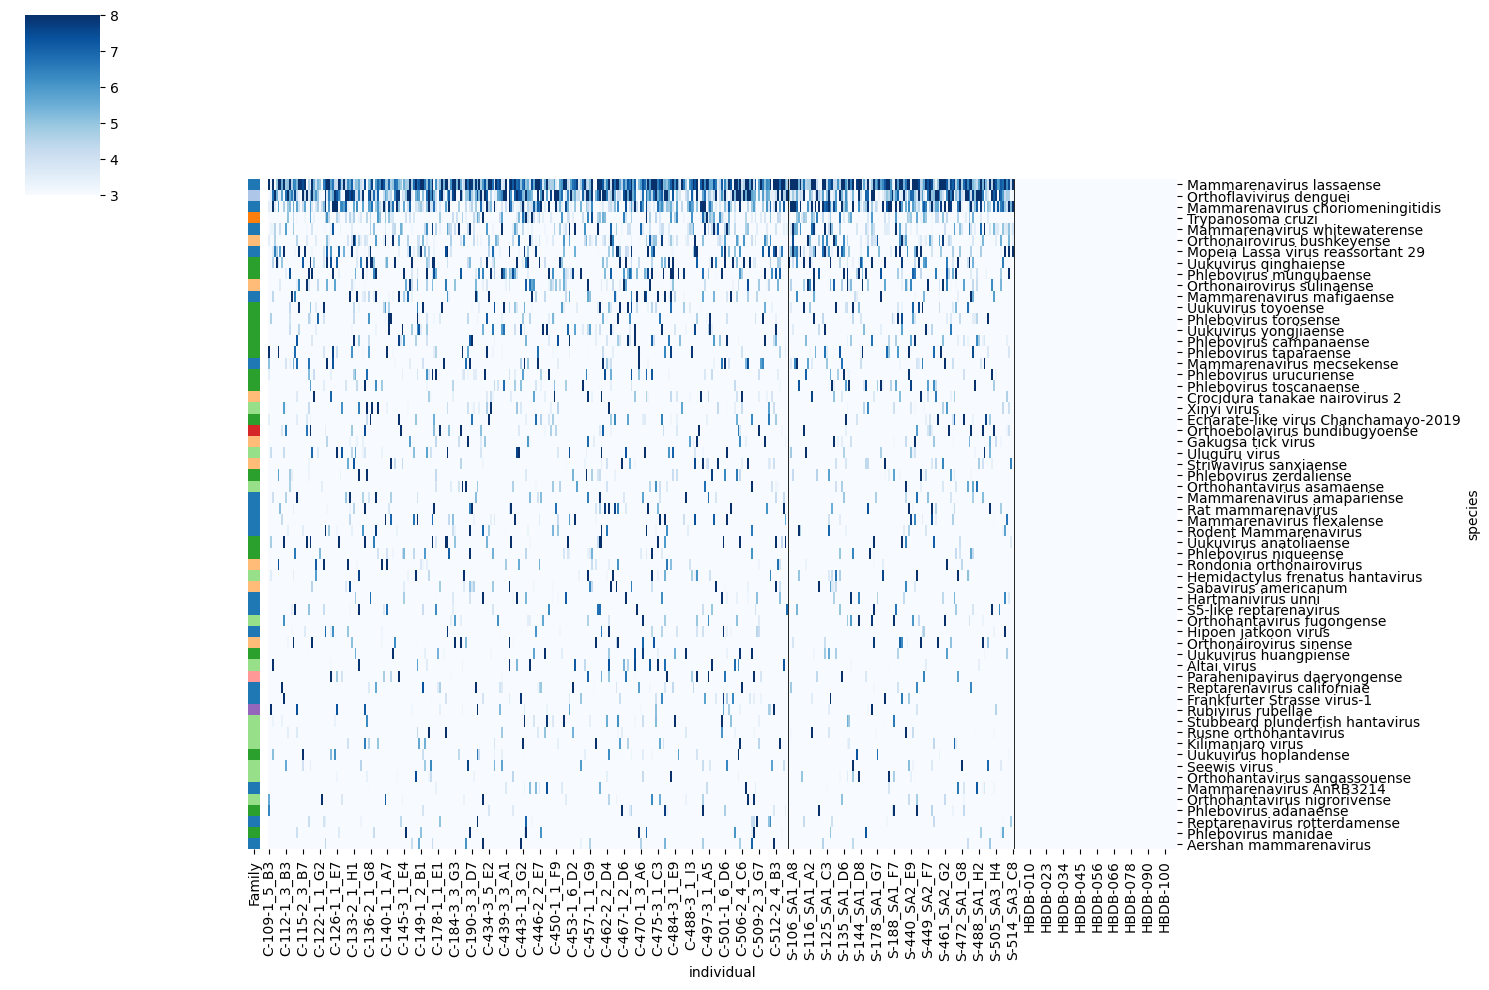

In [ ]:
cutoff = 3

# species -> family
sp_meta = (pep_hits_meta[['species', 'family']]
           .drop_duplicates()
           .set_index('species'))

# filter: pick ONE -> only keep species where people have at least 3 peptides of that species passing z > 3
keep = (topk > cutoff).sum(axis=1) >= 3
topk = topk.loc[keep]

# seroprevalence sort, most to least
seroprev = (topk > cutoff).mean(axis=1)
topk = topk.loc[seroprev.sort_values(ascending=False).index]

# realign metadata to the filtered + sorted rows
sp_meta = sp_meta.loc[topk.index]
families = sp_meta['family'].unique()

palette = sns.color_palette('tab20', n_colors=len(families))
fam_lut = dict(zip(families, palette))
row_colors = sp_meta['family'].map(fam_lut).rename('Family')

g = sns.clustermap(
    topk, row_cluster=False, col_cluster=False,
    row_colors=row_colors, colors_ratio=0.01,
    cmap='Blues', yticklabels=True, figsize=(15, 10),
    rasterized=True, vmin=3, vmax=8,
)

for x in (n_c, n_cs):
    g.ax_heatmap.axvline(x, color="black", lw=0.6)

In [ ]:
sp = (pep_hits_meta[['species', 'genus', 'family']]
      .drop_duplicates().set_index('species')
      .loc[topk.index].copy())

sp['seroprev'] = (topk > cutoff).mean(axis=1)

best = sp.groupby('genus')['seroprev'].idxmax()      # one species per genus
topg = topk.loc[best.values]
sp_g = sp.loc[best.values]

# order by seroprevalence
order = sp_g['seroprev'].sort_values(ascending=False).index
topg, sp_g = topg.loc[order], sp_g.loc[order]

# label rows by genus, keeping the species in parentheses
topg.index = sp_g['genus'] + ' (' + sp_g.index + ')'

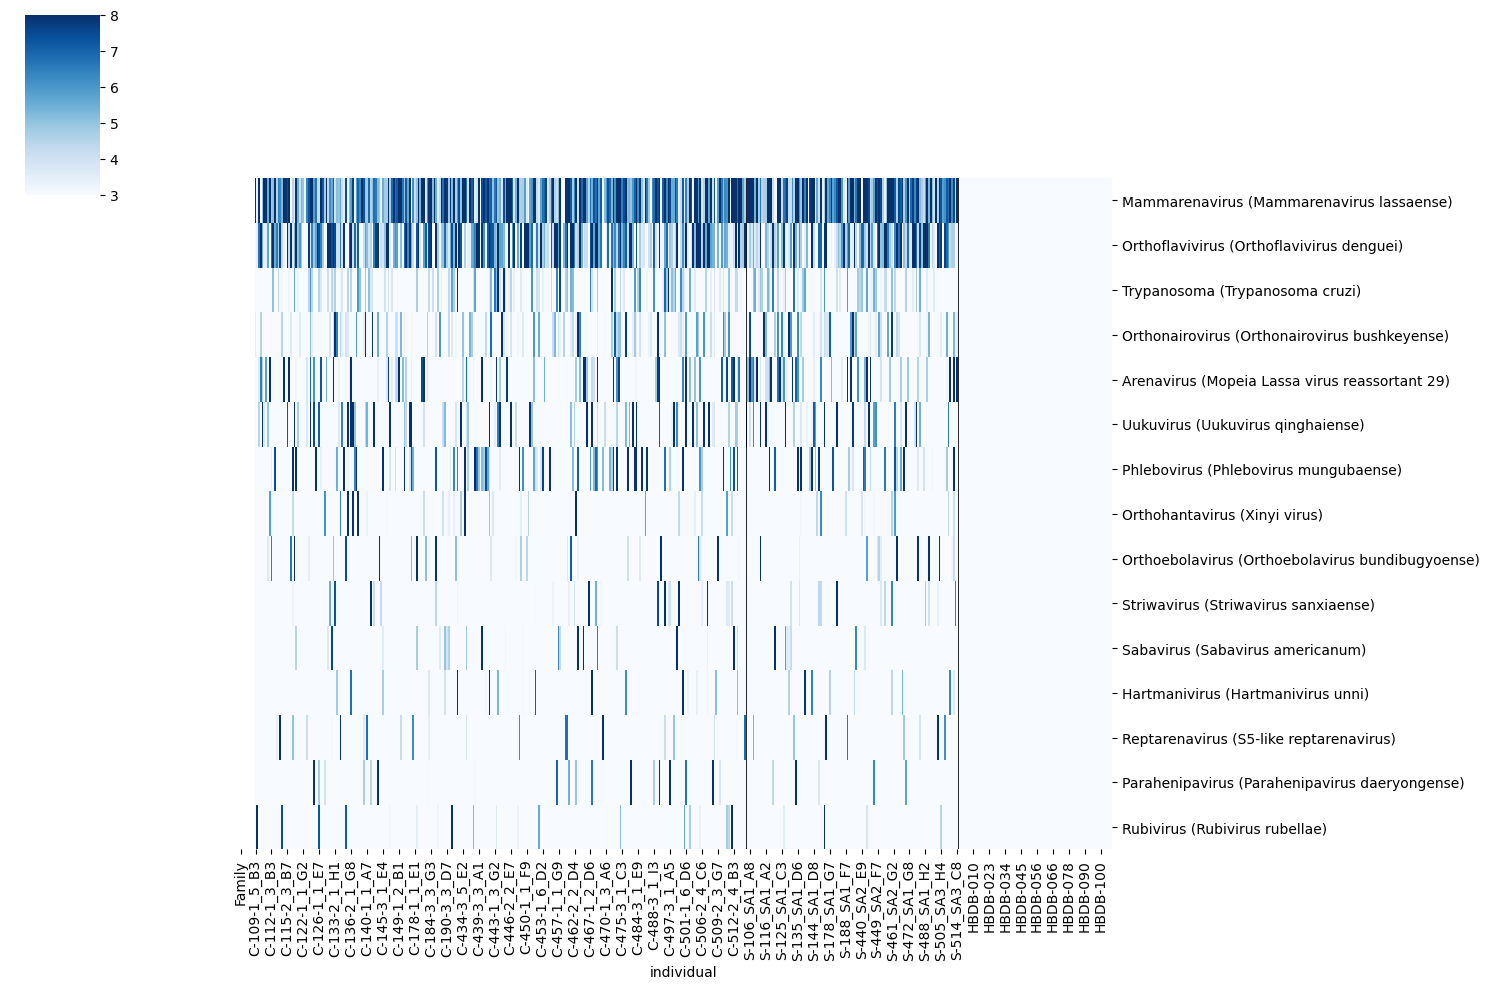

In [ ]:
g = sns.clustermap(
    topg, row_cluster=False, col_cluster=False,
    row_colors=row_colors, colors_ratio=0.01,
    cmap='Blues', yticklabels=True, figsize=(15, 10),
    rasterized=True, vmin=3, vmax=8,
)

for x in (n_c, n_cs):
    g.ax_heatmap.axvline(x, color="black", lw=0.6)

In [ ]:
# per-species z against the healthy distribution
hbdb_cols   = topk.columns[topk.columns.str.startswith('HBDB')]
cohort_cols = topk.columns[~topk.columns.str.startswith('HBDB')]

print(len(hbdb_cols), len(cohort_cols), topk.shape[1])   # should sum to the total
mu  = topk[hbdb_cols].mean(axis=1)
sd  = topk[hbdb_cols].std(axis=1)
topz = topk.sub(mu, axis=0).div(sd, axis=0)

87 397 484
